## **SwinModel**

**Mount Drive & Install Packages**

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Install required packages
!pip install split-folders transformers timm torchmetrics
!pip install --upgrade accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 962.6/962.6 kB 26.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 88.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 71.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 50.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 14.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 111.8 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstal

**Imports**

In [ ]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from sklearn.preprocessing import label_binarize
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision.datasets import ImageFolder
from torchvision import transforms
from transformers import AutoImageProcessor, SwinForImageClassification
from torchmetrics import Accuracy, Precision, Recall, F1Score, AUROC
import splitfolders

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Check if CUDA is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


**Dataset Splitting**

In [ ]:
# Dataset splitting
# Define paths
unsplit_path = "/content/drive/MyDrive/artstyleproject/processeddataset_classification2"
output_path = "/content/processeddataset_classification22"

# Verify and split dataset
if not os.path.exists(unsplit_path):
    print(f"Error: Path not found - {unsplit_path}")
    print("Available folders in /content/drive/MyDrive:")
    !ls "/content/drive/MyDrive"
else:
    print("Dataset found successfully!")
    splitfolders.ratio(
        input=unsplit_path,
        output=output_path,
        seed=42,
        ratio=(0.6, 0.2, 0.2),
        group_prefix=None,
        move=False
    )

Dataset found successfully!


Copying files: 52094 files [58:00, 14.97 files/s]


**Data Loading & Transforms**

In [ ]:
# Define paths for train, validation, and test sets
train_dir = os.path.join(output_path, 'train')
val_dir = os.path.join(output_path, 'val')
test_dir = os.path.join(output_path, 'test')

# Swin Transformer specific transforms
swin_transform = transforms.Compose([
    transforms.Resize((256, 256)),  # Swin typically uses 256x256
    transforms.CenterCrop(224),     # Then center crop to 224x224
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Create datasets
train_dataset = ImageFolder(root=train_dir, transform=swin_transform)
val_dataset = ImageFolder(root=val_dir, transform=swin_transform)
test_dataset = ImageFolder(root=test_dir, transform=swin_transform)

# Split validation set to create plotting_test set
val_size = len(val_dataset)
val_indices = list(range(val_size))
val_split = int(val_size * 0.7)  # 70% for validation, 30% for plotting

val_subset = Subset(val_dataset, val_indices[:val_split])
plotting_test_subset = Subset(val_dataset, val_indices[val_split:])

# Create data loaders
batch_size = 32

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4)
val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False, num_workers=4)
plotting_test_loader = DataLoader(plotting_test_subset, batch_size=batch_size, shuffle=False, num_workers=4)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=4)

# Print dataset sizes
print(f"Training set size: {len(train_dataset)}")
print(f"Validation set size: {len(val_subset)}")
print(f"Plotting test set size: {len(plotting_test_subset)}")
print(f"Real test set size: {len(test_dataset)}")

# Class names
class_names = train_dataset.classes
print("Class names:", class_names)

Training set size: 31255
Validation set size: 7291
Plotting test set size: 3126
Real test set size: 10422
Class names: ['baroque', 'expressionism', 'impressionism', 'realism', 'romanticism']


/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


**Model Initialization**

In [ ]:
# Initialize Swin Transformer model
model_name = "microsoft/swin-tiny-patch4-window7-224"
processor = AutoImageProcessor.from_pretrained(model_name)
model = SwinForImageClassification.from_pretrained(
    model_name,
    num_labels=len(class_names),
    ignore_mismatched_sizes=True
)

# Move model to device
model = model.to(device)

# Print model architecture
print(model)

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/255 [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


config.json:   0%|          | 0.00/71.8k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/113M [00:00<?, ?B/s]

Some weights of SwinForImageClassification were not initialized from the model checkpoint at microsoft/swin-tiny-patch4-window7-224 and are newly initialized because the shapes did not match:
- classifier.bias: found shape torch.Size([1000]) in the checkpoint and torch.Size([5]) in the model instantiated
- classifier.weight: found shape torch.Size([1000, 768]) in the checkpoint and torch.Size([5, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


SwinForImageClassification(
  (swin): SwinModel(
    (embeddings): SwinEmbeddings(
      (patch_embeddings): SwinPatchEmbeddings(
        (projection): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
      )
      (norm): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): SwinEncoder(
      (layers): ModuleList(
        (0): SwinStage(
          (blocks): ModuleList(
            (0): SwinLayer(
              (layernorm_before): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
              (attention): SwinAttention(
                (self): SwinSelfAttention(
                  (query): Linear(in_features=96, out_features=96, bias=True)
                  (key): Linear(in_features=96, out_features=96, bias=True)
                  (value): Linear(in_features=96, out_features=96, bias=True)
                  (dropout): Dropout(p=0.0, inplace=False)
                )
                (output): SwinSelfOutput(
        

**Training Setup**

In [ ]:
# Define optimizer and loss function
optimizer = optim.AdamW(model.parameters(), lr=2e-5)
criterion = nn.CrossEntropyLoss()

# Define metrics
accuracy = Accuracy(task="multiclass", num_classes=len(class_names)).to(device)
precision = Precision(task="multiclass", average='macro', num_classes=len(class_names)).to(device)
recall = Recall(task="multiclass", average='macro', num_classes=len(class_names)).to(device)
f1 = F1Score(task="multiclass", average='macro', num_classes=len(class_names)).to(device)
auroc = AUROC(task="multiclass", num_classes=len(class_names)).to(device)

**Training Function**

In [ ]:
# Training function
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=10):
    train_losses = []
    val_losses = []
    train_accs = []
    val_accs = []

    best_val_loss = float('inf')
    best_model_weights = None

    start_time = time.time()

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        running_corrects = 0

        for inputs, labels in train_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs).logits
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            running_corrects += torch.sum(preds == labels.data)

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_acc = running_corrects.double() / len(train_loader.dataset)

        train_losses.append(epoch_loss)
        train_accs.append(epoch_acc.cpu())

        val_loss, val_acc = evaluate_model(model, val_loader, criterion)
        val_losses.append(val_loss)
        val_accs.append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_weights = model.state_dict().copy()

        print(f'Epoch {epoch+1}/{num_epochs}:')
        print(f'Train Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')
        print(f'Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}')
        print('-' * 10)

    training_time = time.time() - start_time
    print(f'Training complete in {training_time // 60:.0f}m {training_time % 60:.0f}s')
    print(f'Best val Loss: {best_val_loss:.4f}')

    model.load_state_dict(best_model_weights)
    return model, train_losses, val_losses, train_accs, val_accs, training_time

def evaluate_model(model, data_loader, criterion):
    model.eval()
    running_loss = 0.0
    running_corrects = 0

    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs).logits
            loss = criterion(outputs, labels)

            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            running_corrects += torch.sum(preds == labels.data)

    loss = running_loss / len(data_loader.dataset)
    acc = running_corrects.double() / len(data_loader.dataset)

    return loss, acc.cpu()

***Model Training***

In [ ]:
# Train the model
num_epochs = 10
trained_model, train_losses, val_losses, train_accs, val_accs, training_time = train_model(
    model, train_loader, val_loader, criterion, optimizer, num_epochs
)

Epoch 1/10:
Train Loss: 0.6801 Acc: 0.7378
Val Loss: 0.3906 Acc: 0.8569
----------
Epoch 2/10:
Train Loss: 0.3373 Acc: 0.8791
Val Loss: 0.3169 Acc: 0.8814
----------
Epoch 3/10:
Train Loss: 0.1656 Acc: 0.9455
Val Loss: 0.2207 Acc: 0.9231
----------
Epoch 4/10:
Train Loss: 0.0770 Acc: 0.9779
Val Loss: 0.2103 Acc: 0.9309
----------
Epoch 5/10:
Train Loss: 0.0459 Acc: 0.9874
Val Loss: 0.1900 Acc: 0.9399
----------
Epoch 6/10:
Train Loss: 0.0326 Acc: 0.9902
Val Loss: 0.1819 Acc: 0.9442
----------
Epoch 7/10:
Train Loss: 0.0320 Acc: 0.9904
Val Loss: 0.1800 Acc: 0.9480
----------
Epoch 8/10:
Train Loss: 0.0276 Acc: 0.9910
Val Loss: 0.1762 Acc: 0.9482
----------
Epoch 9/10:
Train Loss: 0.0240 Acc: 0.9925
Val Loss: 0.1761 Acc: 0.9501
----------
Epoch 10/10:
Train Loss: 0.0195 Acc: 0.9936
Val Loss: 0.2302 Acc: 0.9318
----------
Training complete in 112m 43s
Best val Loss: 0.1761


**Training Curves**

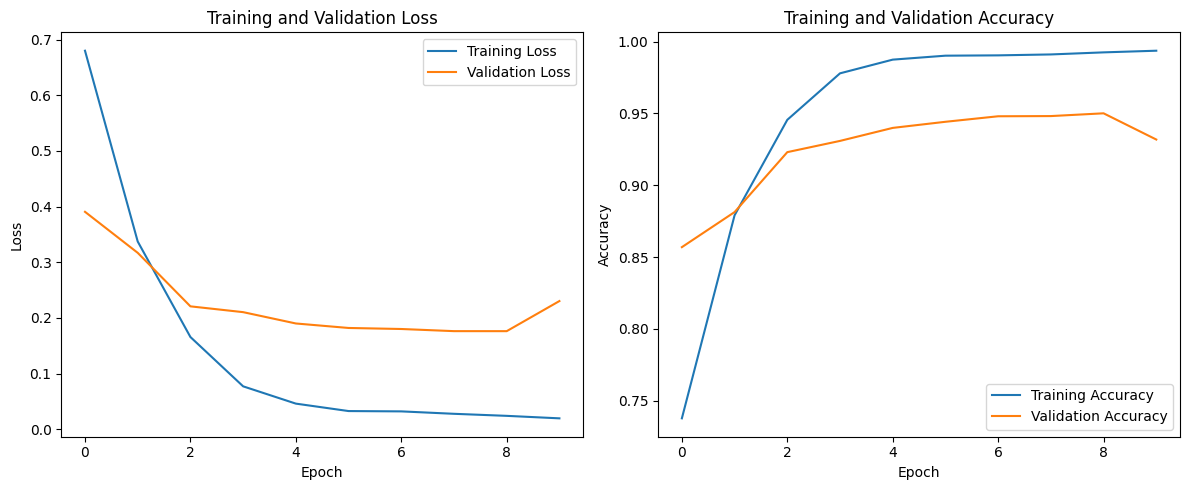

In [ ]:
# Plot training and validation metrics
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot([acc.item() for acc in train_accs], label='Training Accuracy')
plt.plot([acc.item() for acc in val_accs], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

**Testing & Metrics**

In [ ]:
# Test the model
def test_model(model, test_loader):
    model.eval()
    all_preds = []
    all_labels = []
    all_probs = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs).logits
            probs = torch.softmax(outputs, dim=1)
            _, preds = torch.max(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    return all_labels, all_preds, all_probs

start_time = time.time()
test_labels, test_preds, test_probs = test_model(trained_model, test_loader)
inference_time = time.time() - start_time

# Calculate metrics
accuracy_val = accuracy(torch.tensor(test_preds).to(device), torch.tensor(test_labels).to(device))
precision_val = precision(torch.tensor(test_preds).to(device), torch.tensor(test_labels).to(device))
recall_val = recall(torch.tensor(test_preds).to(device), torch.tensor(test_labels).to(device))
f1_val = f1(torch.tensor(test_preds).to(device), torch.tensor(test_labels).to(device))
auroc_val = auroc(torch.tensor(test_probs).to(device), torch.tensor(test_labels).to(device))

print(f"Test Metrics:")
print(f"Accuracy: {accuracy_val:.4f}")
print(f"Precision: {precision_val:.4f}")
print(f"Recall: {recall_val:.4f}")
print(f"F1 Score: {f1_val:.4f}")
print(f"AUROC: {auroc_val:.4f}")
print(f"Inference Time: {inference_time:.2f}s")

print("\nClassification Report:")
print(classification_report(test_labels, test_preds, target_names=class_names))

/tmp/ipython-input-12-3297860239.py:32: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:254.)
  auroc_val = auroc(torch.tensor(test_probs).to(device), torch.tensor(test_labels).to(device))


Test Metrics:
Accuracy: 0.9257
Precision: 0.9262
Recall: 0.9256
F1 Score: 0.9255
AUROC: 0.9931
Inference Time: 161.67s

Classification Report:
               precision    recall  f1-score   support

      baroque       0.95      0.92      0.94      2073
expressionism       0.93      0.98      0.95      2101
impressionism       0.95      0.91      0.93      2093
      realism       0.91      0.89      0.90      2070
  romanticism       0.90      0.92      0.91      2085

     accuracy                           0.93     10422
    macro avg       0.93      0.93      0.93     10422
 weighted avg       0.93      0.93      0.93     10422



 **Confusion Matrix**

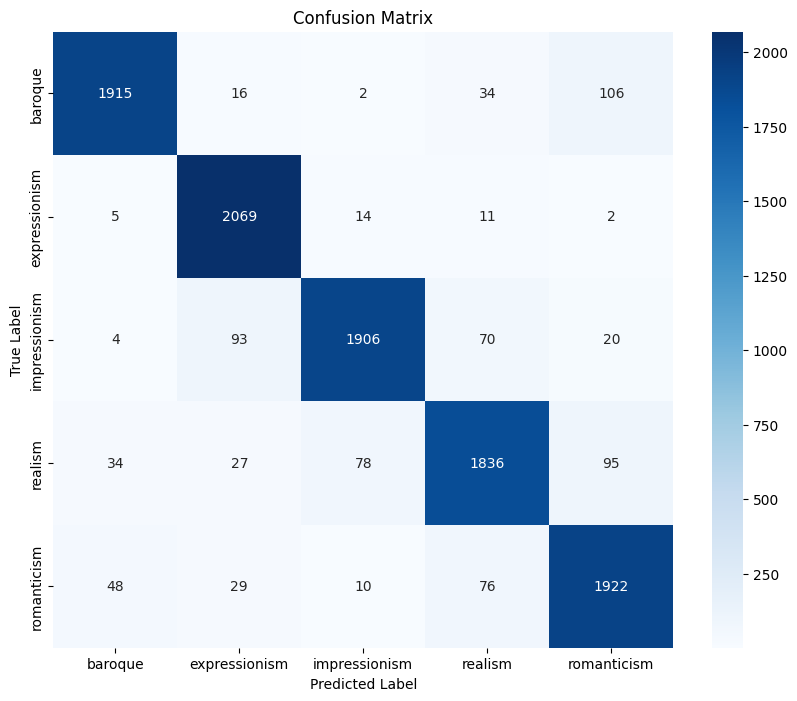

In [ ]:
# Confusion Matrix
plt.figure(figsize=(10, 8))
cm = confusion_matrix(test_labels, test_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

**ROC Curve**

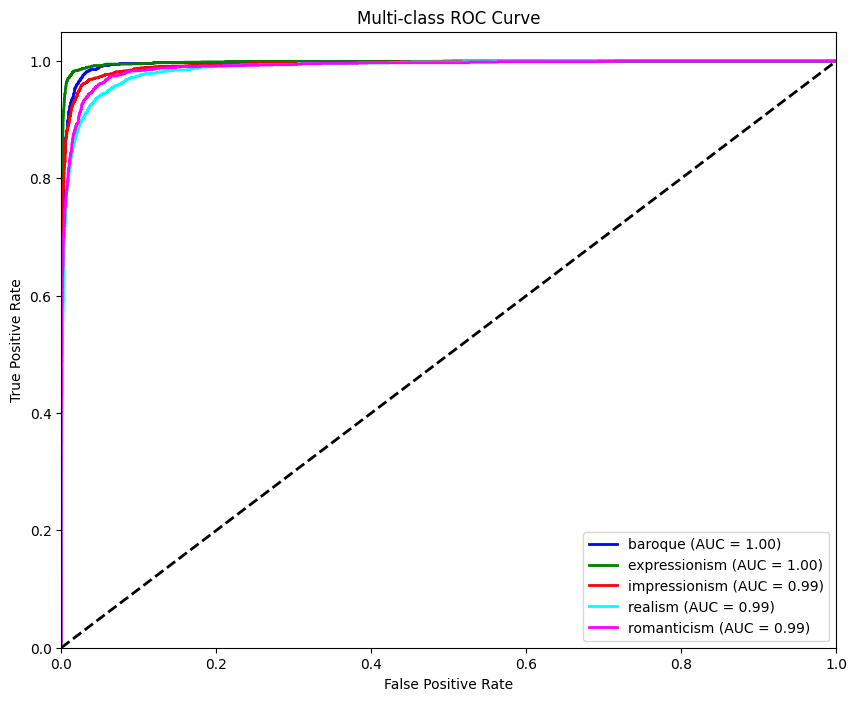

In [ ]:
# ROC Curve
def plot_roc_curve(y_true, y_probs, classes):
    y_true_bin = label_binarize(y_true, classes=np.arange(len(classes)))
    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    for i in range(len(classes)):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], np.array(y_probs)[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    plt.figure(figsize=(10, 8))
    colors = ['blue', 'green', 'red', 'cyan', 'magenta']
    for i, color in zip(range(len(classes)), colors):
        plt.plot(fpr[i], tpr[i], color=color, lw=2,
                 label='{0} (AUC = {1:0.2f})'.format(classes[i], roc_auc[i]))

    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Multi-class ROC Curve')
    plt.legend(loc="lower right")
    plt.show()

plot_roc_curve(test_labels, test_probs, class_names)

**Save Results**

In [ ]:
# Save results
results = {
    'model': 'Swin-T',
    'training_time': training_time,
    'inference_time': inference_time,
    'accuracy': accuracy_val.item(),
    'precision': precision_val.item(),
    'recall': recall_val.item(),
    'f1_score': f1_val.item(),
    'auroc': auroc_val.item(),
    'num_epochs': num_epochs,
    'batch_size': batch_size,
    'classes': class_names
}

results_df = pd.DataFrame([results])
print("\nResults Summary:")
print(results_df)

results_df.to_csv('swin_results.csv', index=False)
torch.save(trained_model.state_dict(), 'swin_art_classifier.pth')


Results Summary:
    model  training_time  inference_time  accuracy  precision    recall  \
0  Swin-T    6762.956013      161.666802  0.925734   0.926169  0.925597   

   f1_score    auroc  num_epochs  batch_size  \
0   0.92552  0.99312          10          32   

                                             classes  
0  [baroque, expressionism, impressionism, realis...  


**Sample Predictions**

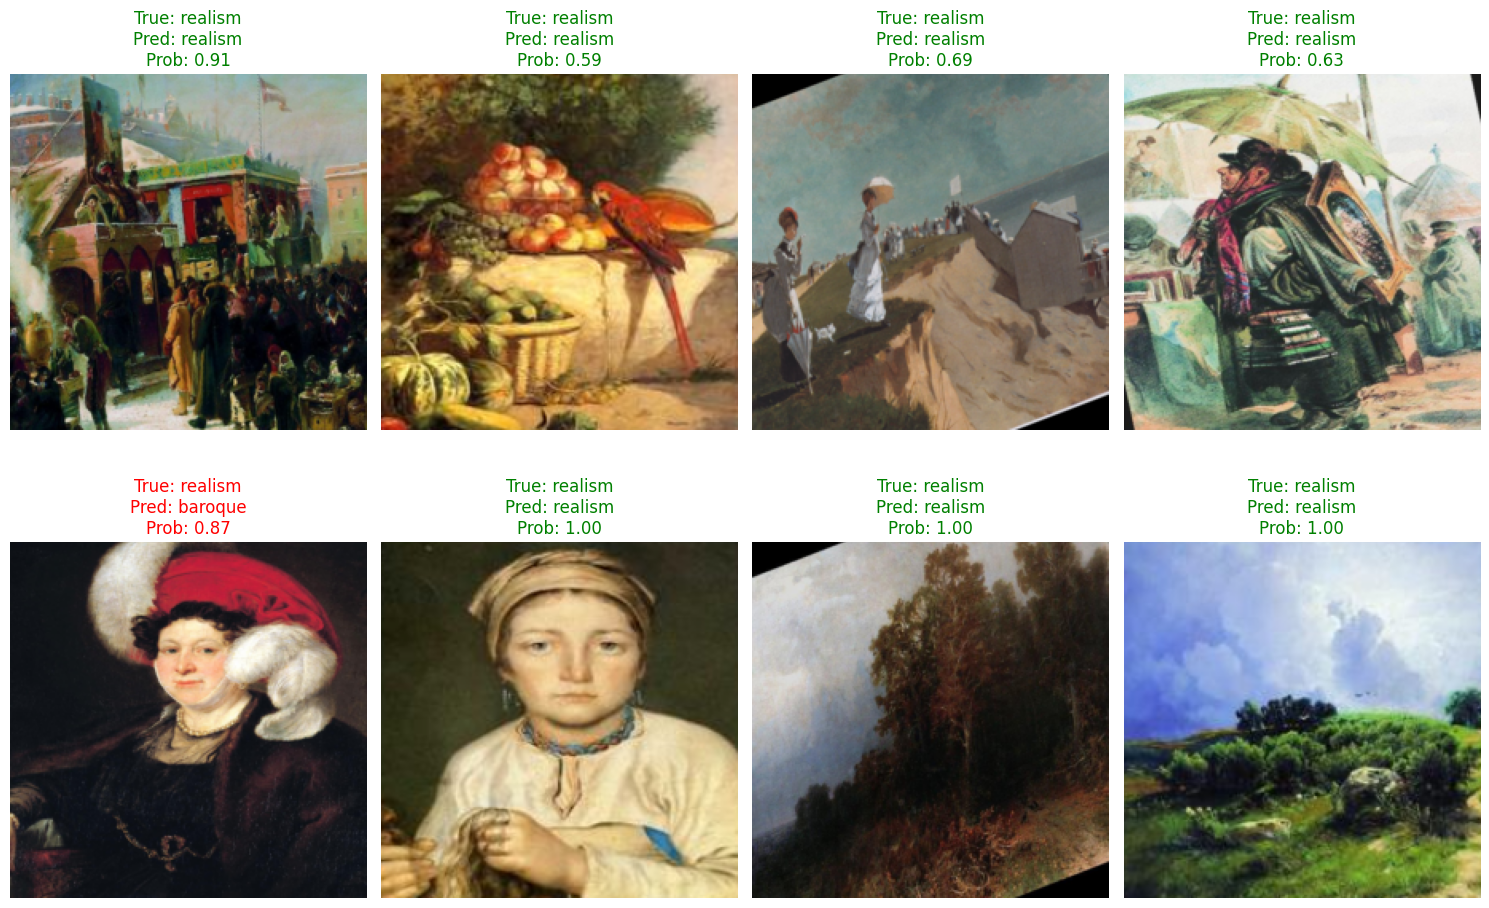

In [ ]:
# Sample predictions
def plot_sample_predictions(model, data_loader, class_names, num_samples=8):
    model.eval()
    images, labels = next(iter(data_loader))
    images = images.to(device)
    labels = labels.to(device)

    with torch.no_grad():
        outputs = model(images).logits
        _, preds = torch.max(outputs, 1)
        probs = torch.softmax(outputs, dim=1)

    images = images.cpu()
    labels = labels.cpu()
    preds = preds.cpu()
    probs = probs.cpu()

    plt.figure(figsize=(15, 10))
    for i in range(num_samples):
        plt.subplot(2, 4, i+1)
        img = images[i].permute(1, 2, 0).numpy()
        img = img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])  # Unnormalize
        img = np.clip(img, 0, 1)

        plt.imshow(img)
        true_label = class_names[labels[i]]
        pred_label = class_names[preds[i]]
        prob = probs[i][preds[i]].item()

        title = f'True: {true_label}\nPred: {pred_label}\nProb: {prob:.2f}'
        color = 'green' if pred_label == true_label else 'red'
        plt.title(title, color=color)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

plot_sample_predictions(trained_model, plotting_test_loader, class_names)